# 5. 1D Lamellar Diffraction Grating: Bloch Modes and Polarization

## Physical Motivation & Learning Objectives
Periodic nanostructures diffract incident plane waves into discrete Bloch modes. In 1D lamellar gratings:
1. Electric fields polarized along grating grooves (**TE polarization**) obey scalar Dirichlet/Neumann conditions.
2. Fields with magnetic fields parallel to grooves (**TM polarization**) feature discontinuous normal electric fields at material interfaces.
3. We compute 1D Bloch modes and compare TE and TM spectra.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Grating Setup: $\Lambda = 760$ nm, Height $= 400$ nm, Fill Factor $= 0.7$


In [2]:
wavelengths = np.linspace(600, 1100, 16)
period = 760.0  # nm
grating_w = int(round(0.7 * period))

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period, grating_w, height_nm=400.0,
    background=materials.Material(1.45),
    inclusion_a=materials.Material(3.5),
    loss=True, lc_bkg=0.01, plt_msh=False
)

def simulate_te(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

def simulate_tm(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TM')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_te = list(executor.map(simulate_te, light_list))
    stacks_tm = list(executor.map(simulate_tm, light_list))


## Comparing TE vs TM Polarized Spectra


<>:9: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:17: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<ipython-input-1-d5884645e69b>:9: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax1.set_title('TE Polarization (E $\parallel$ grooves)', fontsize=12)
<ipython-input-1-d5884645e69b>:17: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax2.set_title('TM Polarization (H $\parallel$ grooves)', fontsize=12)
<ipython-input-1-d5884645e69b>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


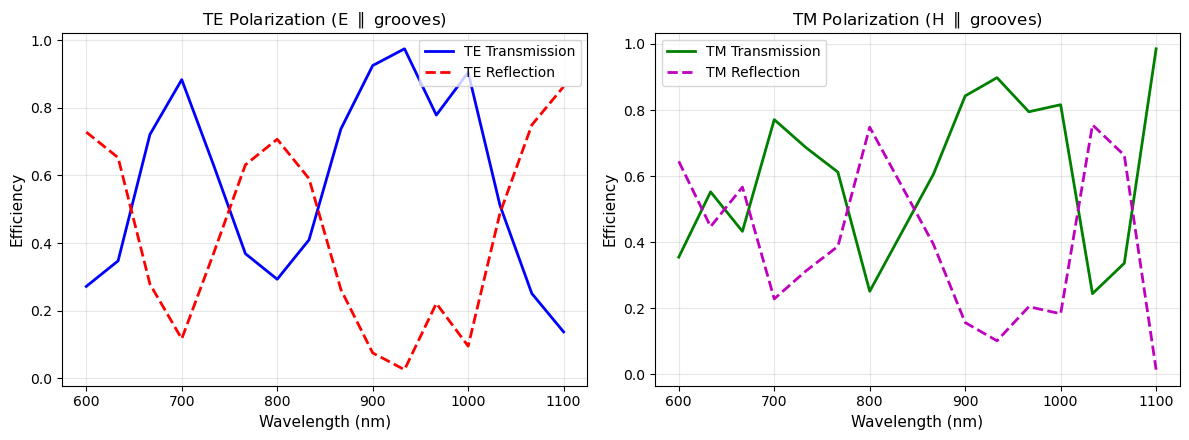

In [3]:
t_te = [float(s.t_list[-1]) for s in stacks_te]
r_te = [float(s.r_list[-1]) for s in stacks_te]
t_tm = [float(s.t_list[-1]) for s in stacks_tm]
r_tm = [float(s.r_list[-1]) for s in stacks_tm]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
ax1.plot(wavelengths, t_te, 'b-', lw=2, label='TE Transmission')
ax1.plot(wavelengths, r_te, 'r--', lw=2, label='TE Reflection')
ax1.set_title('TE Polarization (E $\parallel$ grooves)', fontsize=12)
ax1.set_xlabel('Wavelength (nm)', fontsize=11)
ax1.set_ylabel('Efficiency', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(wavelengths, t_tm, 'g-', lw=2, label='TM Transmission')
ax2.plot(wavelengths, r_tm, 'm--', lw=2, label='TM Reflection')
ax2.set_title('TM Polarization (H $\parallel$ grooves)', fontsize=12)
ax2.set_xlabel('Wavelength (nm)', fontsize=11)
ax2.set_ylabel('Efficiency', fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## Physical Interpretation
- Sharp spectral variations mark **Wood's anomalies** at wavelengths where diffracted orders transition between propagating and evanescent states.
- TE and TM spectra differ dramatically because boundary conditions at the vertical dielectric interfaces depend strongly on polarization.
